# Day4：REINFORCE 为什么需要 baseline

学习者：RedMoon。

上一节看到：没有 baseline 时，短路线的回报 `1.0` 仍然是正数，因此采样到短路线时，策略也可能暂时提高短路线概率。这不是公式失效，而是单次样本噪声。

这次加入一个不依赖动作的状态基线：

$$
A_t=G_t-b(s_t)
$$

其中 $A_t$ 叫 advantage。它回答的是：**这次动作的结果，比当前状态下的通常水平好多少？**

本练习先使用手工给定的 baseline，目的是看清方向；它还不是 Critic，也不学习 baseline 参数。后续 Actor–Critic 会让 Critic 学习状态价值，作为 baseline 的估计。

## 1. 设置本次实验

两条路线的起点折扣回报是：

- 长路线：$1.8$；
- 短路线：$1.0$。

初始策略两个动作各为 `0.5`，所以起点状态的平均回报是：

$$
b(0)=0.5\times1.8+0.5\times1.0=1.4
$$

中间状态无论选哪个动作都会得到 `2.0`，因此设置 $b(1)=2.0$。这些 baseline 数字是教学用的固定参照，不由网络预测。

In [1]:
import os

# 本机 Windows/Anaconda 兼容设置，必须在导入数值库前执行。
if os.name == "nt":
    os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"

import math
import torch
from torch import nn
from torch.distributions import Categorical
import matplotlib.pyplot as plt

gamma = 0.9
learning_rate = 0.1
num_episodes = 1000
seed = 1
eval_episodes = 500

# b(s) 只按状态取值，不按动作取值；本实验中不需要梯度。
baseline_values = torch.tensor([1.4, 2.0], dtype=torch.float32)
print("PyTorch：", torch.__version__)
print("baseline b(s)：", baseline_values.tolist())

PyTorch： 2.10.0+cu128
baseline b(s)： [1.399999976158142, 2.0]


## 2. 环境保持不变

这次不换环境，避免把“加入 baseline 的影响”和“换了任务”的影响混在一起：

```text
长路线：状态0 --动作0，奖励0--> 状态1 --任意动作，奖励2--> 终点
短路线：状态0 --动作1，奖励1----------------------------> 终点
```

两条路线都能到终点，区别只在折扣回报高低。

In [2]:
class TinyChainEnv:
    def __init__(self):
        self.n_states = 2
        self.n_actions = 2
        self.current_state = 0

    def reset(self):
        self.current_state = 0
        return self.current_state

    def step(self, action):
        if action not in (0, 1):
            raise ValueError("action 必须是 0 或 1")
        if self.current_state == 0:
            if action == 0:
                next_state, reward, terminated = 1, 0.0, False
            else:
                next_state, reward, terminated = None, 1.0, True
        elif self.current_state == 1:
            next_state, reward, terminated = None, 2.0, True
        else:
            raise RuntimeError("回合已结束，请先 reset()")
        self.current_state = next_state
        return next_state, reward, terminated, {}


env = TinyChainEnv()

## 3. 定义策略和回报工具

策略仍然从两个动作各 `0.5` 开始。下面的辅助函数与上一节相同，区别在于后面会额外计算：

$$
A_t=G_t-b(s_t)
$$

注意：baseline 只改变乘在 `log_prob` 后面的学习信号，不改变动作采样，也不改变环境奖励。

In [3]:
def state_to_tensor(state, n_states):
    state_tensor = torch.zeros((1, n_states), dtype=torch.float32)
    state_tensor[0, state] = 1.0
    return state_tensor


def make_policy():
    policy = nn.Linear(env.n_states, env.n_actions, bias=False)
    nn.init.zeros_(policy.weight)
    return policy


def get_action_probs(policy, state):
    with torch.no_grad():
        logits = policy(state_to_tensor(state, env.n_states))
        return Categorical(logits=logits).probs.squeeze(0)


def calculate_returns(rewards):
    G = 0.0
    returns = []
    for reward in reversed(rewards):
        G = reward + gamma * G
        returns.append(G)
    returns.reverse()
    return returns


print("起点初始概率：", get_action_probs(make_policy(), 0).tolist())

起点初始概率： [0.5, 0.5]


## 4. 先不训练：直接比较两条路线的 advantage

用固定 baseline `b(0)=1.4`：

| 路线 | $G_0$ | $b(0)$ | $A_0=G_0-b(0)$ | 解释 |
|---|---:|---:|---:|---|
| 长路线 | `1.8` | `1.4` | `+0.4` | 比当前平均表现好，应提高动作 0 |
| 短路线 | `1.0` | `1.4` | `-0.4` | 比当前平均表现差，应降低动作 1 |

关键变化：短路线的回报本身仍然是正数，但它低于 baseline，所以 advantage 变成负数。

In [4]:
path_examples = [
    {"name": "长路线", "states": [0, 1], "rewards": [0.0, 2.0]},
    {"name": "短路线", "states": [0], "rewards": [1.0]},
]

for example in path_examples:
    returns = torch.tensor(calculate_returns(example["rewards"]))
    states = torch.tensor(example["states"])
    advantages = returns - baseline_values[states]
    print(example["name"])
    print("  G_t：", returns.tolist())
    print("  b(s_t)：", baseline_values[states].tolist())
    print("  A_t：", advantages.tolist())

长路线
  G_t： [1.7999999523162842, 2.0]
  b(s_t)： [1.399999976158142, 2.0]
  A_t： [0.3999999761581421, 0.0]
短路线
  G_t： [1.0]
  b(s_t)： [1.399999976158142]
  A_t： [-0.3999999761581421]


## 5. 控制同一条路线，观察一次更新方向

下面不进行随机采样，而是人为指定动作序列，只为了公平比较同一条经历在两种写法下的方向：

- 长路线：状态 `[0, 1]`，动作 `[0, 1]`，奖励 `[0, 2]`；
- 短路线：状态 `[0]`，动作 `[1]`，奖励 `[1]`。

这不是正式训练循环；它是一个受控实验。每个版本都从同样的初始策略开始，且 `log_prob` 仍然来自策略网络、保留计算图。

In [5]:
def controlled_update(states, actions, rewards, use_baseline):
    policy = make_policy()
    optimizer = torch.optim.SGD(policy.parameters(), lr=learning_rate)
    log_probs = []

    for state, action in zip(states, actions):
        distribution = Categorical(
            logits=policy(state_to_tensor(state, env.n_states))
        )
        action_tensor = torch.tensor([action])
        log_probs.append(distribution.log_prob(action_tensor).squeeze(0))

    returns = torch.tensor(calculate_returns(rewards))
    time_steps = torch.arange(len(returns), dtype=torch.float32)
    if use_baseline:
        state_tensor = torch.tensor(states)
        signal = returns - baseline_values[state_tensor]
    else:
        signal = returns
    weights = (gamma ** time_steps) * signal
    loss = -(torch.stack(log_probs) * weights).sum()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    return {
        "weights": weights.tolist(),
        "loss": loss.item(),
        "start_probs": get_action_probs(policy, 0).tolist(),
    }


for name, states, actions, rewards in [
    ("长路线", [0, 1], [0, 1], [0.0, 2.0]),
    ("短路线", [0], [1], [1.0]),
]:
    plain = controlled_update(states, actions, rewards, use_baseline=False)
    centered = controlled_update(states, actions, rewards, use_baseline=True)
    print(name)
    print("  不用 baseline 的损失权重：", plain["weights"])
    print("  使用 baseline 的损失权重：", centered["weights"])
    print("  不用 baseline，更新后起点概率：", plain["start_probs"])
    print("  使用 baseline，更新后起点概率：", centered["start_probs"])


长路线
  不用 baseline 的损失权重： [1.7999999523162842, 1.7999999523162842]
  使用 baseline 的损失权重： [0.3999999761581421, 0.0]
  不用 baseline，更新后起点概率： [0.5448789000511169, 0.45512115955352783]
  使用 baseline，更新后起点概率： [0.5099986791610718, 0.490001380443573]
短路线
  不用 baseline 的损失权重： [1.0]
  使用 baseline 的损失权重： [-0.3999999761581421]
  不用 baseline，更新后起点概率： [0.47502076625823975, 0.5249791741371155]
  使用 baseline，更新后起点概率： [0.5099986791610718, 0.490001380443573]


受控实验应看到：

- 长路线：不管有没有 baseline，动作 0 都会被提高；baseline 只是把信号从 `1.8` 居中为 `0.4`，更新更温和。
- 短路线：没有 baseline 时，正回报 `1.0` 会提高被采样的动作 1；有 baseline 时，`A_0=-0.4`，动作 1 被降低，所以动作 0 的概率反而提高。

baseline 没有告诉算法“动作 1 的真实回报是多少”，也没有枚举没执行的动作；它只是提供一个状态层面的比较标准。

## 6. 把 baseline 放进多局训练

这次并行跑两种版本：

1. 原始 REINFORCE：使用 `G_t`；
2. 带固定 baseline：使用 `A_t=G_t-b(s_t)`。

两种版本从相同初始策略开始，训练局数、学习率、折扣因子和随机种子都相同。比较的重点不是谁永远更快，而是观察：带 baseline 后，单样本方向更符合“高于或低于通常水平”的判断，曲线波动通常更小。

这里的 baseline 是固定的真实参照，只用于教学。实际任务通常不知道准确的 $V(s)$，因此会用 Critic 估计它；那就是 Actor–Critic 中 `advantage` 的来源。

In [6]:
def collect_episode(policy, env):
    state = env.reset()
    log_probs, rewards, states, trajectory = [], [], [], []
    while True:
        distribution = Categorical(
            logits=policy(state_to_tensor(state, env.n_states))
        )
        action_tensor = distribution.sample()
        action = int(action_tensor.item())
        log_prob = distribution.log_prob(action_tensor).squeeze(0)
        next_state, reward, terminated, _ = env.step(action)
        log_probs.append(log_prob)
        states.append(state)
        rewards.append(reward)
        trajectory.append((state, action, reward, next_state, terminated))
        if terminated:
            break
        state = next_state
    return log_probs, states, rewards, trajectory


def train(use_baseline, seed):
    torch.manual_seed(seed)
    policy = make_policy()
    optimizer = torch.optim.SGD(policy.parameters(), lr=learning_rate)
    initial_p = get_action_probs(policy, 0)[0].item()
    history = {
        "long_probs": [initial_p],
        "sample_returns": [],
        "expected_returns": [1 + 0.8 * initial_p],
        "advantages_at_start": [],
        "losses": [],
        "downward_updates": 0,
        "trajectories": [],
    }

    for episode in range(num_episodes):
        p_before = history["long_probs"][-1]
        log_probs, states, rewards, trajectory = collect_episode(policy, env)
        returns = torch.tensor(calculate_returns(rewards), dtype=torch.float32)
        state_tensor = torch.tensor(states)
        if use_baseline:
            signal = returns - baseline_values[state_tensor]
        else:
            signal = returns
        time_steps = torch.arange(len(returns), dtype=torch.float32)
        weights = (gamma ** time_steps) * signal
        loss = -(torch.stack(log_probs) * weights).sum()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        p_after = get_action_probs(policy, 0)[0].item()
        history["long_probs"].append(p_after)
        history["sample_returns"].append(returns[0].item())
        history["expected_returns"].append(1 + 0.8 * p_after)
        history["advantages_at_start"].append(signal[0].item())
        history["losses"].append(loss.item())
        history["downward_updates"] += int(p_after < p_before)
        if episode < 5:
            history["trajectories"].append({
                "episode": episode + 1,
                "trajectory": trajectory,
                "signal": signal.tolist(),
                "p_before": p_before,
                "p_after": p_after,
            })
    return policy, history


plain_policy, plain_history = train(use_baseline=False, seed=seed)
baseline_policy, baseline_history = train(use_baseline=True, seed=seed)

print("原始 REINFORCE：")
print(f"  长路线概率：{plain_history['long_probs'][0]:.4f} -> "
      f"{plain_history['long_probs'][-1]:.4f}")
print("  概率下降次数：", plain_history["downward_updates"])
print("带固定 baseline：")
print(f"  长路线概率：{baseline_history['long_probs'][0]:.4f} -> "
      f"{baseline_history['long_probs'][-1]:.4f}")
print("  概率下降次数：", baseline_history["downward_updates"])

原始 REINFORCE：
  长路线概率：0.5000 -> 0.9945
  概率下降次数： 36
带固定 baseline：
  长路线概率：0.5000 -> 0.9937
  概率下降次数： 0


## 7. 前几局：看 baseline 怎样改变短路线样本的信号

下面只打印前五局，避免把 1000 局日志刷满。两种版本的随机种子相同，因此开头采样到的路线可以直接对照；参数更新不同后，后续随机动作也可能逐渐分开。

关注 `signal`：

- 原始版本的短路线起点信号是 `+1.0`；
- baseline 版本的短路线起点信号是 `-0.4`。

这就是“正回报”和“正优势”不是同一件事。

In [7]:
for plain, centered in zip(
    plain_history["trajectories"], baseline_history["trajectories"]
):
    plain_route = "长路线" if len(plain["trajectory"]) == 2 else "短路线"
    centered_route = "长路线" if len(centered["trajectory"]) == 2 else "短路线"
    print(f"第 {plain['episode']} 局")
    print(f"  原始：{plain_route}，signal={plain['signal']}，"
          f"p0 {plain['p_before']:.4f}->{plain['p_after']:.4f}")
    print(f"  baseline：{centered_route}，signal={centered['signal']}，"
          f"p0 {centered['p_before']:.4f}->{centered['p_after']:.4f}")

第 1 局
  原始：短路线，signal=[1.0]，p0 0.5000->0.4750
  baseline：短路线，signal=[-0.3999999761581421]，p0 0.5000->0.5100
第 2 局
  原始：短路线，signal=[1.0]，p0 0.4750->0.4514
  baseline：短路线，signal=[-0.3999999761581421]，p0 0.5100->0.5202
第 3 局
  原始：长路线，signal=[1.7999999523162842, 2.0]，p0 0.4514->0.5006
  baseline：长路线，signal=[0.3999999761581421, 0.0]，p0 0.5202->0.5298
第 4 局
  原始：短路线，signal=[1.0]，p0 0.5006->0.4756
  baseline：短路线，signal=[-0.3999999761581421]，p0 0.5298->0.5403
第 5 局
  原始：短路线，signal=[1.0]，p0 0.4756->0.4520
  baseline：短路线，signal=[-0.3999999761581421]，p0 0.5403->0.5510


## 8. 对比训练曲线

左图比较起点动作 0 的概率；右图比较已知环境下的精确期望回报。baseline 不改变优化目标的理论期望，只改变单次样本的表达方式和方差。

图中曲线不需要逐点单调上升；重要的是观察整体趋势与短路线样本造成的波动差异。

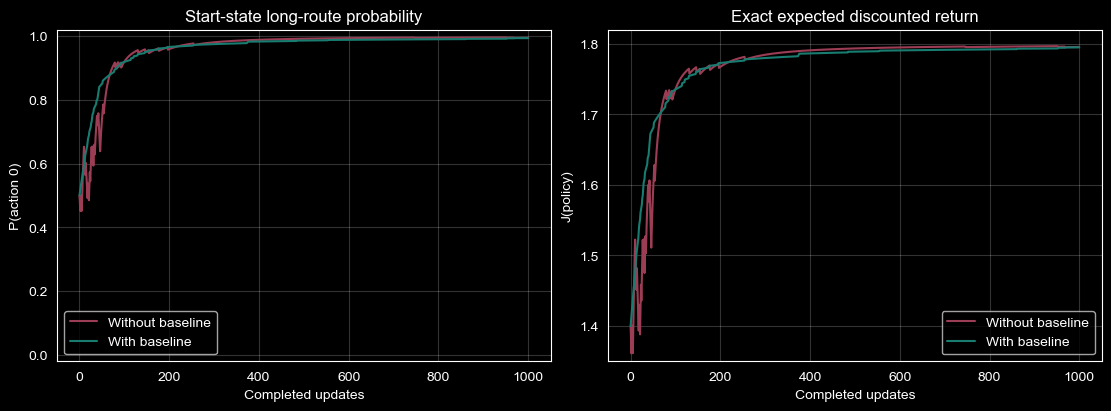

In [8]:
episodes_axis = range(num_episodes + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
axes[0].plot(episodes_axis, plain_history["long_probs"],
             label="Without baseline", color="#9b3d55")
axes[0].plot(episodes_axis, baseline_history["long_probs"],
             label="With baseline", color="#187c70")
axes[0].set(title="Start-state long-route probability",
            xlabel="Completed updates", ylabel="P(action 0)", ylim=(-0.02, 1.02))
axes[0].legend()
axes[1].plot(episodes_axis, plain_history["expected_returns"],
             label="Without baseline", color="#9b3d55")
axes[1].plot(episodes_axis, baseline_history["expected_returns"],
             label="With baseline", color="#187c70")
axes[1].set(title="Exact expected discounted return",
            xlabel="Completed updates", ylabel="J(policy)", ylim=(1.35, 1.82))
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

## 9. 冻结带 baseline 训练后的策略，再做评估

baseline 只在训练时参与损失计算。训练结束后，策略仍然只是一个动作分布；评估时不再计算 baseline，也不调用 `backward()` 或 `step()`。

评估继续区分：

- 按概率采样 500 局，估计路线选择率；
- 用一次贪心动作展示完整轨迹。

评估前后参数应完全相同。

In [9]:
@torch.no_grad()
def evaluate(policy, greedy=False):
    state = env.reset()
    rewards, trajectory = [], []
    while True:
        logits = policy(state_to_tensor(state, env.n_states))
        if greedy:
            action = int(logits.argmax(dim=1).item())
        else:
            action = int(Categorical(logits=logits).sample().item())
        next_state, reward, terminated, _ = env.step(action)
        rewards.append(reward)
        trajectory.append((state, action, reward, next_state, terminated))
        if terminated:
            break
        state = next_state
    return calculate_returns(rewards)[0], trajectory


baseline_policy.eval()
weights_before_eval = baseline_policy.weight.detach().clone()
torch.manual_seed(2026)
eval_returns, eval_trajectories = [], []
for _ in range(eval_episodes):
    episode_return, trajectory = evaluate(baseline_policy)
    eval_returns.append(episode_return)
    eval_trajectories.append(trajectory)
eval_long_count = sum(trajectory[0][1] == 0 for trajectory in eval_trajectories)
eval_mean = sum(eval_returns) / len(eval_returns)
greedy_return, greedy_trajectory = evaluate(baseline_policy, greedy=True)
final_p = get_action_probs(baseline_policy, 0)[0].item()

print(f"带 baseline 的最终长路线概率：{final_p:.4%}")
print(f"采样评估长路线：{eval_long_count}/{eval_episodes} = "
      f"{eval_long_count / eval_episodes:.4%}")
print(f"采样评估平均折扣回报：{eval_mean:.4f}")
print("贪心完整轨迹：", greedy_trajectory)
print("贪心折扣回报：", greedy_return)
print("评估前后参数完全相同：", torch.equal(weights_before_eval, baseline_policy.weight))

带 baseline 的最终长路线概率：99.3729%
采样评估长路线：496/500 = 99.2000%
采样评估平均折扣回报：1.7936
贪心完整轨迹： [(0, 0, 0.0, 1, False), (1, 0, 2.0, None, True)]
贪心折扣回报： 1.8
评估前后参数完全相同： True


## 10. 自动检查本节结论

检查目标不是要求每个随机种子都得到完全一样的最终数值，而是确认本节的结构和默认实验事实：

- baseline 不依赖动作，也不参与梯度；
- 短路线的 advantage 确实为负；
- 受控实验中 baseline 改变了短路线的更新方向；
- 多局训练正常结束，参数确实更新；
- 冻结评估不修改参数，贪心轨迹走到终点。

通过这些检查不等于已经掌握 Actor–Critic；后续还要解释 Critic 怎样学习 baseline。

In [10]:
checks = 0
assert not baseline_values.requires_grad
checks += 1

long_returns = torch.tensor(calculate_returns([0.0, 2.0]))
short_returns = torch.tensor(calculate_returns([1.0]))
assert torch.allclose(long_returns - baseline_values[torch.tensor([0, 1])],
                      torch.tensor([0.4, 0.0]))
checks += 1
assert torch.allclose(short_returns - baseline_values[torch.tensor([0])],
                      torch.tensor([-0.4]))
checks += 1

long_plain = controlled_update([0, 1], [0, 1], [0.0, 2.0], False)
long_centered = controlled_update([0, 1], [0, 1], [0.0, 2.0], True)
short_plain = controlled_update([0], [1], [1.0], False)
short_centered = controlled_update([0], [1], [1.0], True)
assert long_plain["start_probs"][0] > 0.5 and long_centered["start_probs"][0] > 0.5
checks += 1
assert short_plain["start_probs"][0] < 0.5 and short_centered["start_probs"][0] > 0.5
checks += 1

assert len(plain_history["sample_returns"]) == len(baseline_history["sample_returns"]) == num_episodes
checks += 1
assert plain_history["downward_updates"] > 0
checks += 1
assert baseline_history["downward_updates"] == 0
checks += 1
assert baseline_history["long_probs"][-1] > baseline_history["long_probs"][0]
checks += 1
assert all(math.isfinite(x) for x in baseline_history["losses"])
checks += 1
assert len(eval_returns) == eval_episodes
checks += 1
assert torch.equal(weights_before_eval, baseline_policy.weight)
checks += 1
assert len(greedy_trajectory) == 2 and greedy_trajectory[0][1] == 0
checks += 1
assert greedy_trajectory[-1][4] and math.isclose(greedy_return, 1.8)
checks += 1
assert torch.allclose(get_action_probs(baseline_policy, 0).sum(), torch.tensor(1.0))
checks += 1
assert checks == 15
print(f"通过 {checks} 项检查：baseline 信号、训练更新与冻结评估。")

通过 15 项检查：baseline 信号、训练更新与冻结评估。


## 11. 本节结论

baseline 不负责直接告诉策略哪个动作一定最好，它只是把回报变成相对表现：

$$
A_t=G_t-b(s_t)
$$

- $A_t>0$：这次结果高于当前状态的参照水平，提高实际动作概率；
- $A_t<0$：这次结果低于参照水平，降低实际动作概率；
- $A_t=0$：这条样本对 Actor 没有直接的策略梯度贡献。

baseline 的核心价值是降低更新方差，让正负信号更能表达“相对好坏”。它不能保证每次更新都改善，也不能替代 Critic 对价值的学习。